**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 8**
Regresión Lineal

---

EQUIPO 67
*   NOMBRE: Adolfo Siliceo Vásquez, Héctor André Simental Gaxiola, Carlos Armando Solis Contreras, José Carlos Sierra Pérez
*   MATRÍCULA: A01841467, A01840739, A01841611, A01055689

En esta actividad trabajarás con el archivo `diamonds_dataset.csv`, basado en un conjunto de datos sobre características de diamantes, disponible en el paquete ggplot2 de R y en repositorios públicos de análisis de datos.

Los datos fueron recopilados para analizar el precio de los diamantes en función de sus propiedades físicas y cualidades de corte, color y claridad. Los indicadores incluidos son:

* `carat`: Peso del diamante en quilates
* `cut`: Calidad del corte del diamante (Fair, Good, Very Good, Premium, Ideal)
* `color`: Color del diamante, de D (mejor) a J (peor)
* `clarity`: Claridad del diamante (I1, SI2, SI1, VS2, VS1, VVS2, VVS1, IF)
* `depth`: Profundidad total del diamante como porcentaje: z / mean(x, y)
* `table`: Ancho de la tabla del diamante como porcentaje de x
* `x`: Longitud en mm
* `y`: Ancho en mm
* `z`: Profundidad en mm
* `price`: Precio del diamante en dólares estadounidenses. Es la variable de salida o *target*

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [14]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, RobustScaler
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import root_mean_squared_error, r2_score

1. Descarga el archivo: `diamonds_dataset.csv` y guarda, en un dataframe (`diamonds_df`), todos sus registros.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.
* Verifica si alguna columna contiene valores faltantes.
* Si existen registros duplicados, elimínalos del dataframe y reinicia el índice para que se mantenga consecutivo.

In [15]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [16]:
diamonds_df = pd.read_csv('/content/drive/MyDrive/Ciencia Analitica de Datos/Semana8/diamonds_dataset.csv')

diamonds_df.info()
print("\n")
print(diamonds_df.nunique())
print("\n")
print(diamonds_df.isnull().sum())
print("\n")
print('Duplicados:', diamonds_df.duplicated().sum())

diamonds_df = diamonds_df.drop_duplicates().reset_index(drop=True)

print(diamonds_df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53916 entries, 0 to 53915
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53916 non-null  float64
 1   cut      53916 non-null  object 
 2   color    53916 non-null  object 
 3   clarity  53916 non-null  object 
 4   depth    53916 non-null  float64
 5   table    53916 non-null  float64
 6   x        53916 non-null  float64
 7   y        53916 non-null  float64
 8   z        53916 non-null  float64
 9   price    53916 non-null  int64  
dtypes: float64(6), int64(1), object(3)
memory usage: 4.1+ MB


carat        271
cut            5
color          7
clarity        8
depth        184
table        127
x            550
y            549
z            371
price      11595
dtype: int64


carat      0
cut        0
color      0
clarity    0
depth      0
table      0
x          0
y          0
z          0
price      0
dtype: int64


Duplicados: 145
(53771, 10)


--------------
El conjunto de datos contenia inicialmente 53,916 registros. Después de eliminar 145 registros duplicados, quedaron 53,771 registros. No se encontraron valores faltantes.
--------------

2. Obtén las estadísticas descriptivas, separando las variables numéricas y las categóricas. De estas últimas incluye las tablas de frecuencia.
* Para las variables numéricas genera histogramas y boxplots para explorar la distribución y la dispersión.
* Para las variables categóricas utiliza diagramas de barras para visualizar la frecuencia de cada categoría.

              carat         depth         table             x             y  \
count  53771.000000  53771.000000  53771.000000  53771.000000  53771.000000   
mean       0.797323     61.748160     57.457635      5.731280      5.734618   
std        0.472474      1.429519      2.233192      1.118102      1.138982   
min        0.200000     43.000000     43.000000      3.730000      3.680000   
25%        0.400000     61.000000     56.000000      4.710000      4.720000   
50%        0.700000     61.800000     57.000000      5.700000      5.710000   
75%        1.040000     62.500000     59.000000      6.540000      6.540000   
max        4.500000     79.000000     95.000000     10.230000     58.900000   

                  z         price  
count  53771.000000  53771.000000  
mean       3.539774   3930.320545  
std        0.701677   3984.687429  
min        1.070000    326.000000  
25%        2.910000    951.000000  
50%        3.530000   2401.000000  
75%        4.030000   5323.500000  


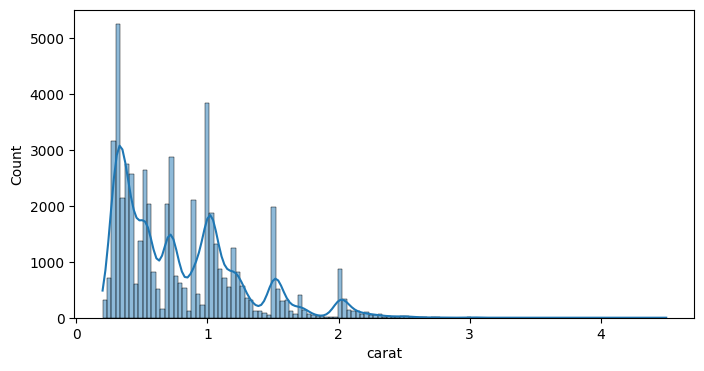

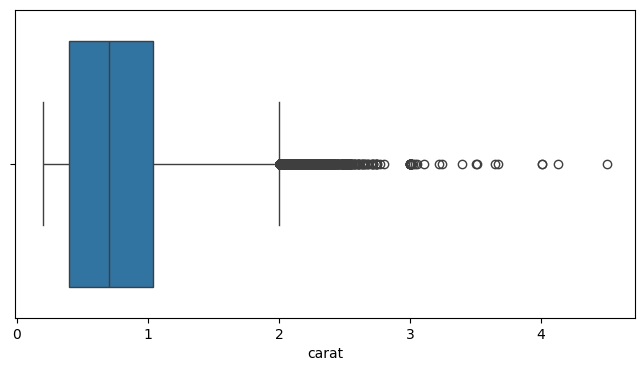

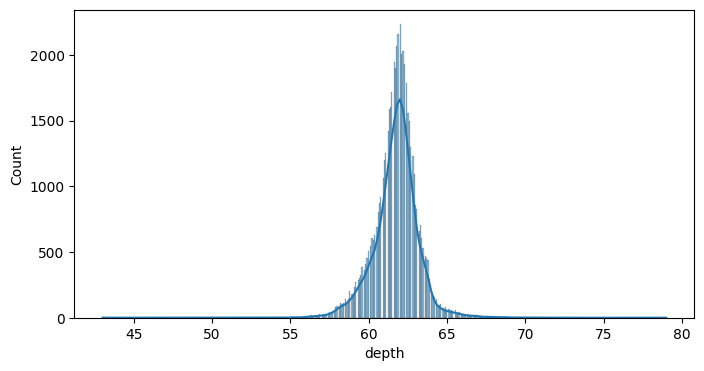

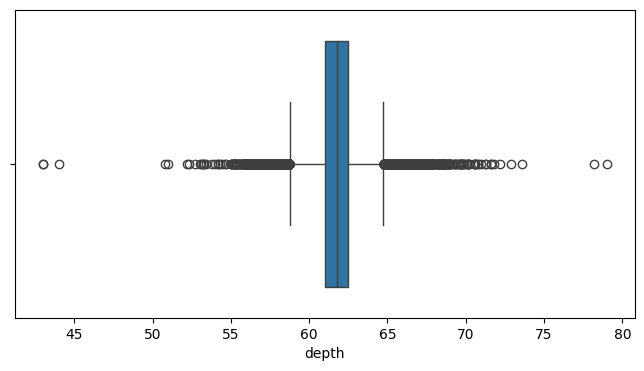

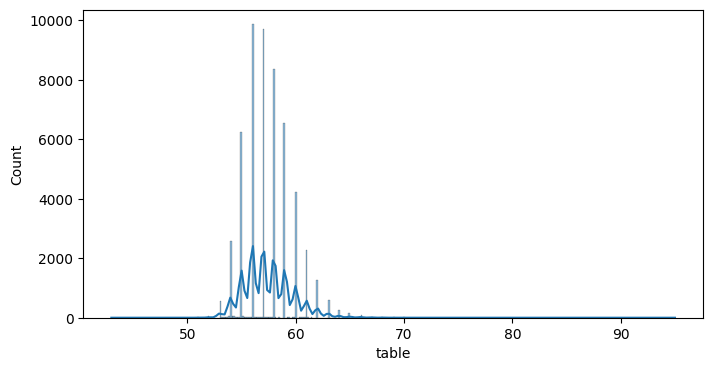

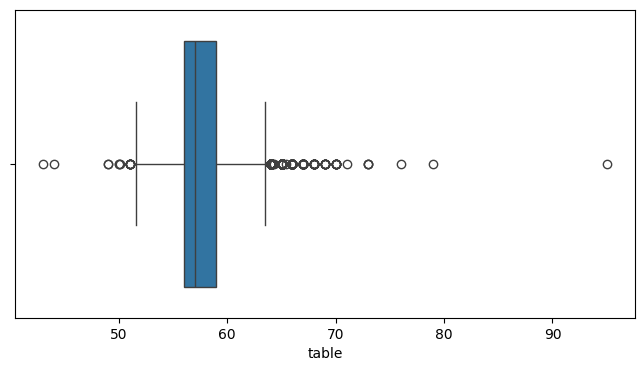

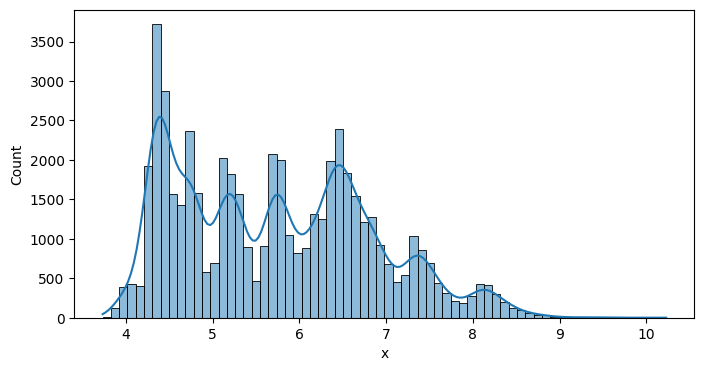

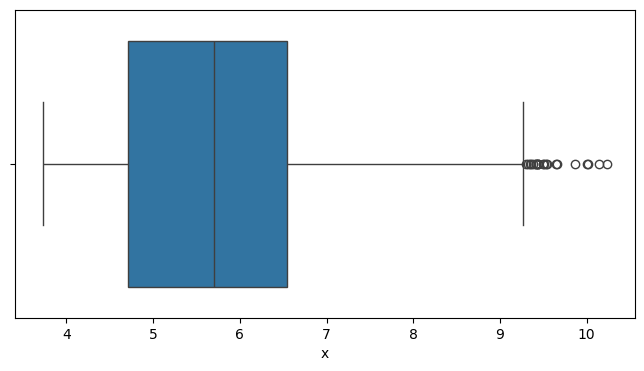

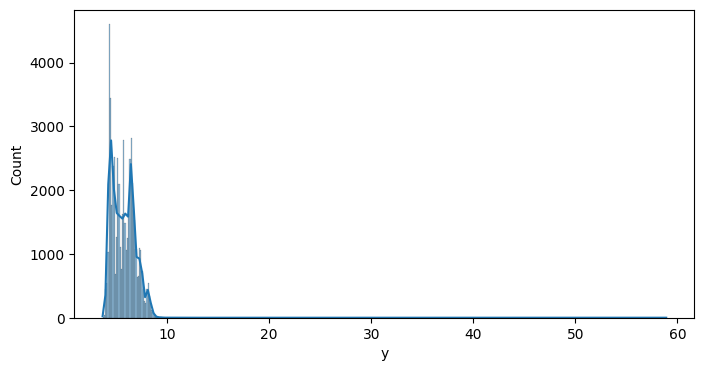

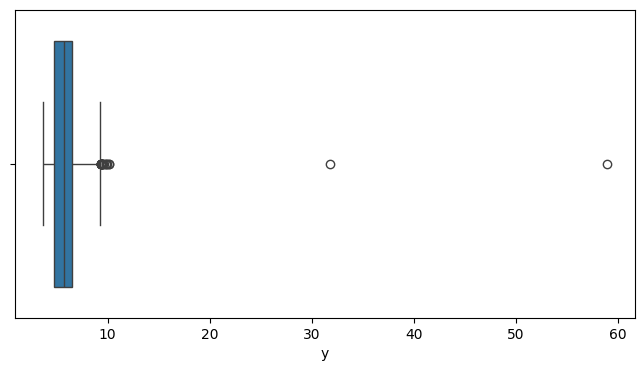

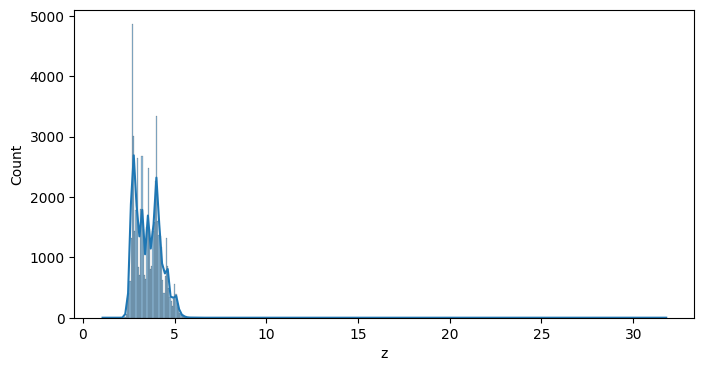

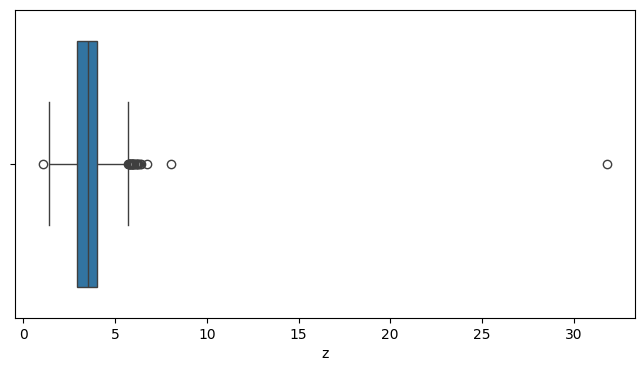

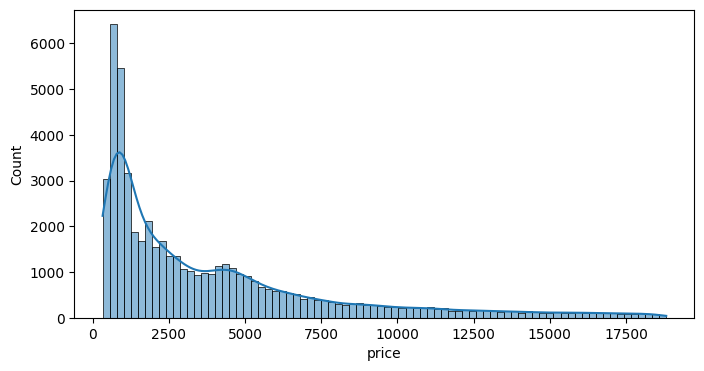

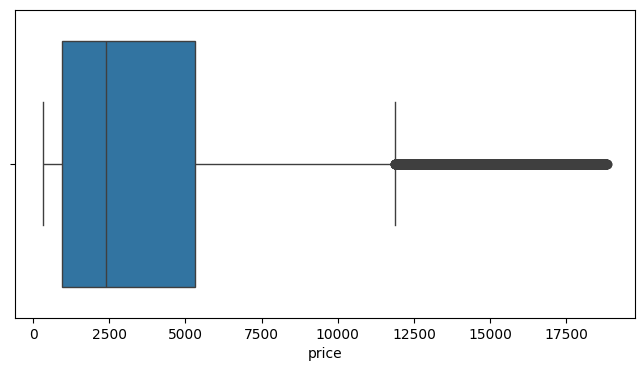

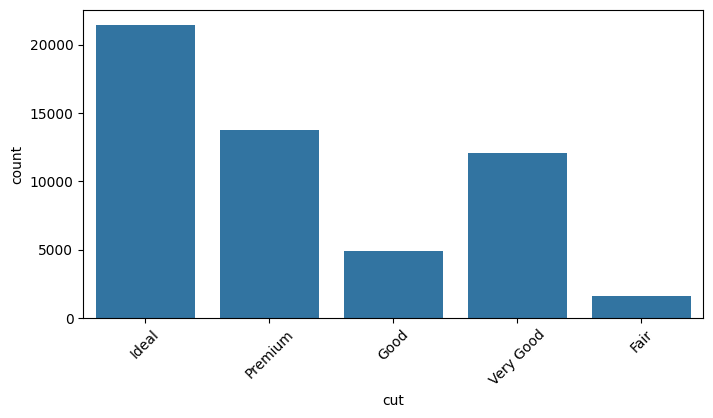

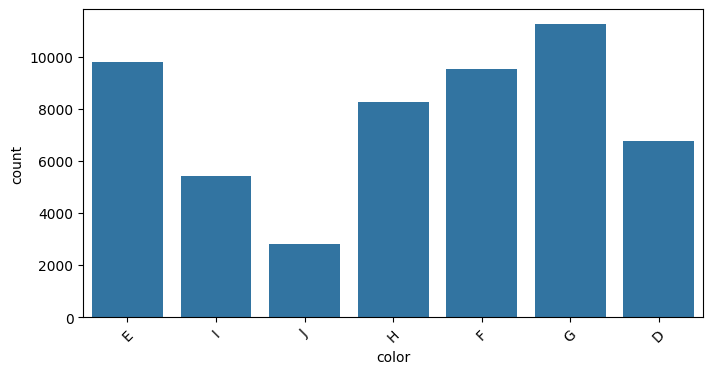

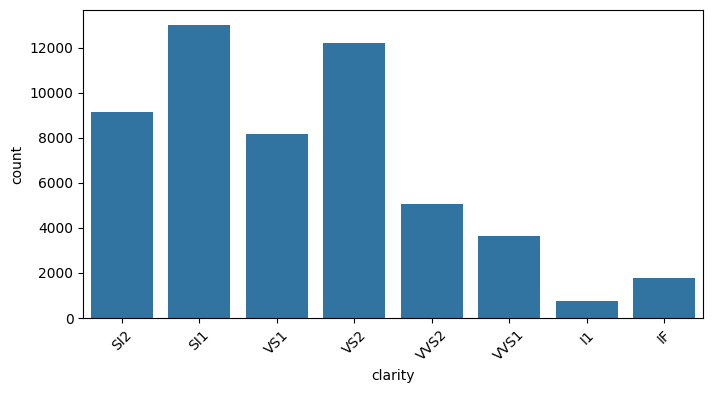

In [17]:
print(diamonds_df.describe())
print(diamonds_df.describe(include='object'))

for columna in ['cut', 'color', 'clarity']:
    print('\n', diamonds_df[columna].value_counts())

for columna in diamonds_df.select_dtypes(include=np.number).columns:
    plt.figure(figsize=(8, 4))
    sns.histplot(data=diamonds_df, x=columna, kde=True)
    plt.show()

    plt.figure(figsize=(8, 4))
    sns.boxplot(data=diamonds_df, x=columna)
    plt.show()

for columna in ['cut', 'color', 'clarity']:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=diamonds_df, x=columna)
    plt.xticks(rotation=45)
    plt.show()

--------------
La mayoría de los diamantes tienen precios relativamente bajos, mientras que unos pocos presentan precios considerablemente mayores. El corte Ideal es el más frecuente y el color G es el que aparece con mayor frecuencia.
--------------

3. Explora relaciones bivariadas en el conjunto de datos mediante gráficos:
* Boxplots que muestren la distribución del precio para cada categoría de color, asegurándose de que las categorías se muestren en el orden de calidad de diamante de mejor a peor: D, E, F, G, H, I, J.
* ¿La tendencia de los precios se comporta como esperabas? Identifica si alguna otra variable podría estar influyendo en la tendencia observada por color y comenta tus observaciones.
* Gráfico de dispersión del precio frente al peso de los diamantes, coloreando los puntos según la categoría de calidad del corte.
* ¿Qué relación se observa entre el peso del diamante y su precio según la calidad del corte?

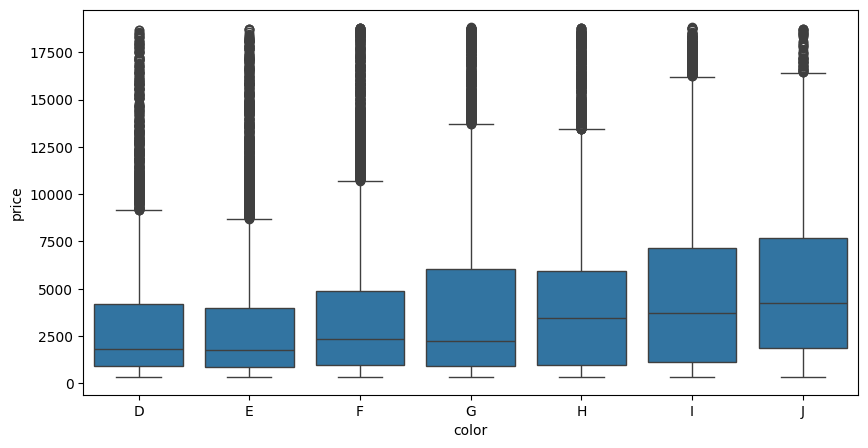

             price     carat
color                       
D      3170.874278  0.657951
E      3079.608020  0.657957
F      3726.776820  0.736603
G      3999.088502  0.770811
H      4477.103194  0.910400
I      5075.924130  1.024047
J      5321.884327  1.161467


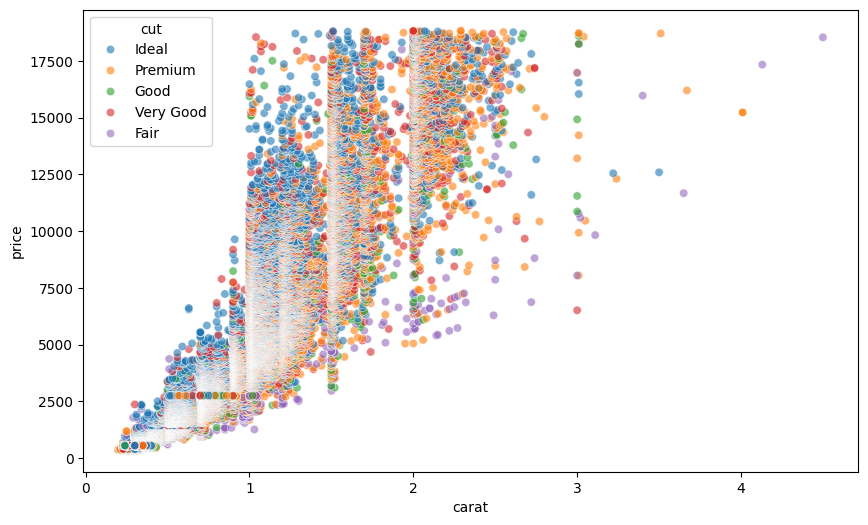

In [18]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=diamonds_df,
    x='color',
    y='price',
    order=['D', 'E', 'F', 'G', 'H', 'I', 'J']
)

plt.show()

print(diamonds_df.groupby('color')[['price', 'carat']].mean())

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=diamonds_df,
    x='carat',
    y='price',
    hue='cut',
    alpha=0.6
)

plt.show()

--------------
Es visible que los diamantes de colores inferiores, como I y J, tienen precios promedio mas altos. Esto se debe principalmente a que tambien presentan mayor peso en quilates. Por lo tanto, el peso influye considerablemente en esta tendencia.
--------------

--------------
Relación peso-precio según el corte: el diagrama de dispersión muestra una relación fuerte y positiva entre carat y price (r = 0.9218), pero claramente no lineal: la nube se curva hacia arriba, de modo que el precio crece más que proporcionalmente con el peso.

La calidad del corte tiene un efecto secundario para un mismo peso, los diamantes 'Ideal' tienden a ubicarse ligeramente por encima y los 'Fair' por debajo, pero la separación entre categorías es débil frente al efecto del peso. La correlación 'carat'–'price' se mantiene alta en todas las categorías de corte ('Ideal' 0.9312, 'Very Good' 0.9268, 'Premium' 0.9250, 'Good' 0.9223, 'Fair' 0.8582).

 los diamantes 'Ideal' son los más baratos en promedio (3,462 contra 4,332 de los 'Fair') porque también son los más livianos (0.703 contra 1.041 quilates). Es el mismo efecto de confusión observado con el color: el peso domina sobre los atributos de calidad.

--------------

4. Dibuja un mapa de calor con la matriz de correlación para las variables numéricas del conjunto de datos.
* Identifica los pares de variables cuya correlación sea superior a 0.9 e imprímelos.
* Analiza la correlación entre los predictores (excluyendo `price`), identifica si un único predictor captura información que también está presente en varios otros y elimina los predictores redundantes para simplificar la complejidad de los modelos que construirás más adelante.
* Vuelve a generar el mapa de calor para verificar que ya no queden predictores altamente correlacionados.

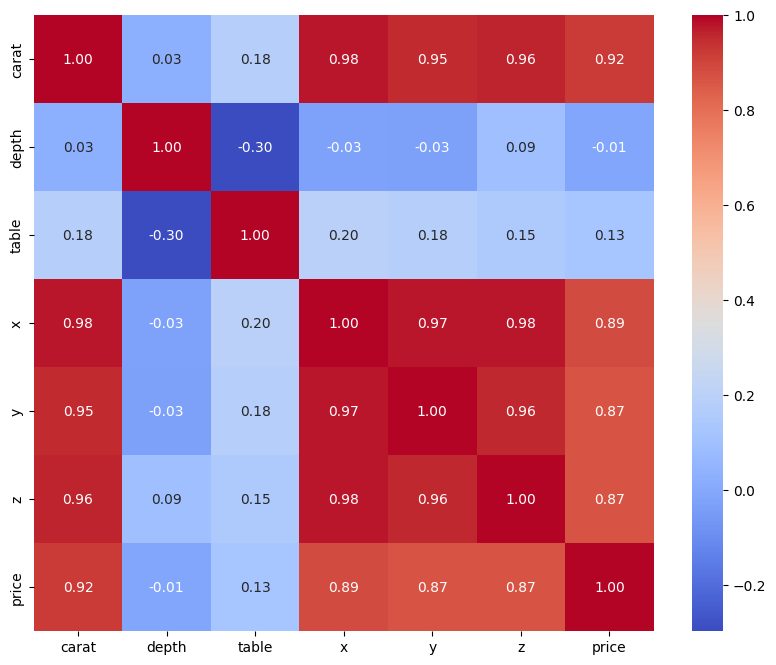

carat  x        0.978108
       y        0.954222
       z        0.961213
       price    0.921846
x      y        0.974799
       z        0.975361
y      z        0.956587
dtype: float64


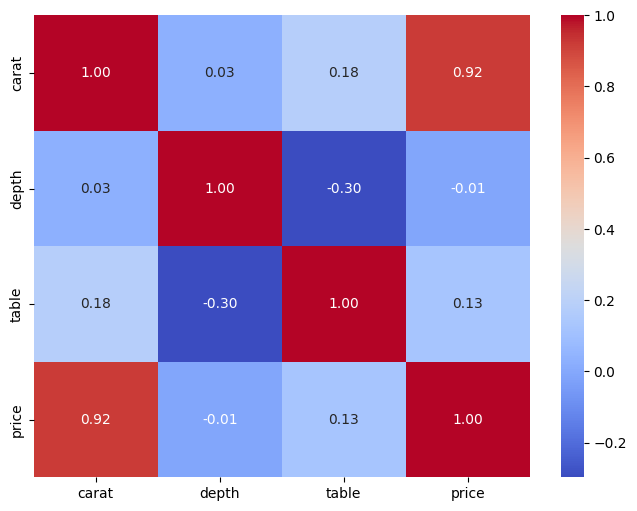

In [19]:
correlacion = diamonds_df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlacion, annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

correlaciones_altas = correlacion.where(
    np.triu(np.ones(correlacion.shape), k=1).astype(bool)
).stack()

print(correlaciones_altas[correlaciones_altas > 0.9])

diamonds_df = diamonds_df.drop(columns=['x', 'y', 'z'])

correlacion = diamonds_df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlacion, annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

--------------
La variable carat tiene la relacion mas fuerte con el precio, con una correlacion aproximada de 0.92. Se eliminaron las variables x, y y z porque presentan una alta correlación con carat y aportan informacion similar.
--------------

5. Construye un modelo de regresión simple utilizando únicamente la variable predictora que tenga la mayor correlación con `price`. Para ello:
* Asigna esta variable a `X` y `price` a `y` y divide el conjunto de datos en entrenamiento y prueba (80:20), usando `random_state=1` para garantizar reproducibilidad.
* Entrena un modelo con `LinearRegression()` de scikit-learn y evalúalo en el conjunto de prueba utilizando las métricas `RMSE` (Root Mean Squared Error) y `R²` (coeficiente de determinación).
* Añade los valores obtenidos a un dataframe de resultados, que incluya el nombre del modelo (*Baseline*) y una columna para cada métrica.
* Muestra la ecuación de la regresión lineal utilizando el intercepto y el coeficiente asociado al predictor. La ecuación debe tener la forma:
> `price = intercepto + coeficiente × predictor`

In [20]:
X = diamonds_df[['carat']]
y = diamonds_df['price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)

modelo_baseline = LinearRegression()
modelo_baseline.fit(X_train, y_train)

y_pred_baseline = modelo_baseline.predict(X_test)

rmse_baseline = root_mean_squared_error(y_test, y_pred_baseline)
r2_baseline = r2_score(y_test, y_pred_baseline)

resultados_df = pd.DataFrame({
    'Modelo': ['Baseline'],
    'RMSE': [rmse_baseline],
    'R2': [r2_baseline]
})

print(resultados_df)

print(
    f"price = {modelo_baseline.intercept_:.2f} + "
    f"{modelo_baseline.coef_[0]:.2f} x carat"
)

     Modelo        RMSE       R2
0  Baseline  1532.43849  0.84618
price = -2276.79 + 7792.73 x carat


--------------
Utilizando unicamente el peso del diamante, se obtuvo un R² de 0.8462 y un RMSE de 1,532.44 dólares. Esto significa que el modelo explica aproximadamente el 84.62% de las variaciones en los precios con un error promedio de ±1,532 dólares (39% del precio medio del conjunto)..
--------------

6. Utiliza todas las variables como predictoras para crear un segundo modelo:
* Haz la asignación correspondiente en `X` y `y` y divide en entrenamiento y prueba usando la misma configuración del ejercicio anterior.
* Prepara un transformador, denominado `preprocessing`, para aplicar escalamiento robusto a los predictores numéricos y codificación ordinal a los categóricos. Asegúrate de respetar el orden correcto de cada categoría, tal como se indica en la descripción de las variables.
* Construye un pipeline que combine el transformador creado con un modelo de regresión lineal.
* Añade los valores de las métricas obtenidas al dataframe de resultados, utilizando como nombre del modelo *Ordinal_Robust*.

In [21]:
X = diamonds_df.drop(columns=['price'])
y = diamonds_df['price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)

numericas = ['carat', 'depth', 'table']
categoricas = ['cut', 'color', 'clarity']

ordenes = [
    ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal'],
    ['D', 'E', 'F', 'G', 'H', 'I', 'J'],
    ['I1', 'SI2', 'SI1', 'VS2', 'VS1', 'VVS2', 'VVS1', 'IF']
]

preprocessing = ColumnTransformer([
    ('num', RobustScaler(), numericas),
    ('cat', OrdinalEncoder(categories=ordenes), categoricas)
])

modelo_ordinal = make_pipeline(
    preprocessing,
    LinearRegression()
)

modelo_ordinal.fit(X_train, y_train)

y_pred_ordinal = modelo_ordinal.predict(X_test)

rmse_ordinal = root_mean_squared_error(y_test, y_pred_ordinal)
r2_ordinal = r2_score(y_test, y_pred_ordinal)

resultados_df.loc[len(resultados_df)] = [
    'Ordinal_Robust',
    rmse_ordinal,
    r2_ordinal
]

print(resultados_df)

           Modelo         RMSE        R2
0        Baseline  1532.438490  0.846180
1  Ordinal_Robust  1216.822219  0.903016


--------------
Al incorporar las caracteristicas de corte, color y claridad, el R² aumento a 0.9030 y el RMSE bajó de 1,532.44 a 1,216.82 dólares, una reducción del 20.6% en el error. Esto demuestra que considerar mas caracteristicas permite obtener mejores predicciones.
--------------

7. Prepara otro transformador, llamado `preprocessing2`, que aplique escalamiento Min-Max a los predictores numéricos y codificación one-hot a los categóricos, asegurando `drop='first'` para prevenir multicolinealidad en las variables dummies generadas.
* Construye otro pipeline utilizando este nuevo transformador y, a continuación, entrena y evalúa el modelo.
* Añade los valores de las métricas obtenidas al dataframe de resultados, utilizando como nombre del modelo *OHE_MinMax*.

In [22]:
preprocessing2 = ColumnTransformer([
    ('num', MinMaxScaler(), numericas),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categoricas)
])

modelo_ohe = make_pipeline(
    preprocessing2,
    LinearRegression()
)

modelo_ohe.fit(X_train, y_train)

y_pred_ohe = modelo_ohe.predict(X_test)

rmse_ohe = root_mean_squared_error(y_test, y_pred_ohe)
r2_ohe = r2_score(y_test, y_pred_ohe)

resultados_df.loc[len(resultados_df)] = [
    'OHE_MinMax',
    rmse_ohe,
    r2_ohe
]

print(resultados_df)

           Modelo         RMSE        R2
0        Baseline  1532.438490  0.846180
1  Ordinal_Robust  1216.822219  0.903016
2      OHE_MinMax  1142.519131  0.914499


--------------
Se obtuvo un R² de 0.9145 y un RMSE de 1,142.52 dólares. La codificacion One-Hot produjo mejores resultados que la codificacion ordinal, ya que permitio representar las categorias de manera independiente sin imponer distancias uniformes entre niveles de calidad..
--------------

8. Modifica el pipeline anterior para emplear regresión polinomial de segundo grado y evalúa si esto mejora el ajuste del modelo.
* Añade los valores de las métricas obtenidas al dataframe de resultados, utilizando como nombre del modelo *PolynomialDegree2*.

In [23]:
modelo_polynomial = make_pipeline(
    preprocessing2,
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

modelo_polynomial.fit(X_train, y_train)

y_pred_polynomial = modelo_polynomial.predict(X_test)

rmse_polynomial = root_mean_squared_error(y_test, y_pred_polynomial)
r2_polynomial = r2_score(y_test, y_pred_polynomial)

resultados_df.loc[len(resultados_df)] = [
    'PolynomialDegree2',
    rmse_polynomial,
    r2_polynomial
]

print(resultados_df)

              Modelo         RMSE        R2
0           Baseline  1532.438490  0.846180
1     Ordinal_Robust  1216.822219  0.903016
2         OHE_MinMax  1142.519131  0.914499
3  PolynomialDegree2   749.036382  0.963250


--------------
Este modelo obtuvo el mejor resultado, con un R²  de 0.9633 y un RMSE aproximado de 749 dolares. Por lo tanto, las relaciones entre las diferentes cualidades de los diamantes y su precio no son completamente lineales.
--------------

9. Ordena el dataframe de resultados según el `R²`, de manera que el modelo con mejor desempeño aparezca primero.
* Para dicho modelo, crea un gráfico de dispersión de los valores reales frente a los predichos, e incluye una línea diagonal de referencia para indicar una predicción perfecta.

              Modelo         RMSE        R2
0  PolynomialDegree2   749.036382  0.963250
1         OHE_MinMax  1142.519131  0.914499
2     Ordinal_Robust  1216.822219  0.903016
3           Baseline  1532.438490  0.846180
Mejor modelo: PolynomialDegree2


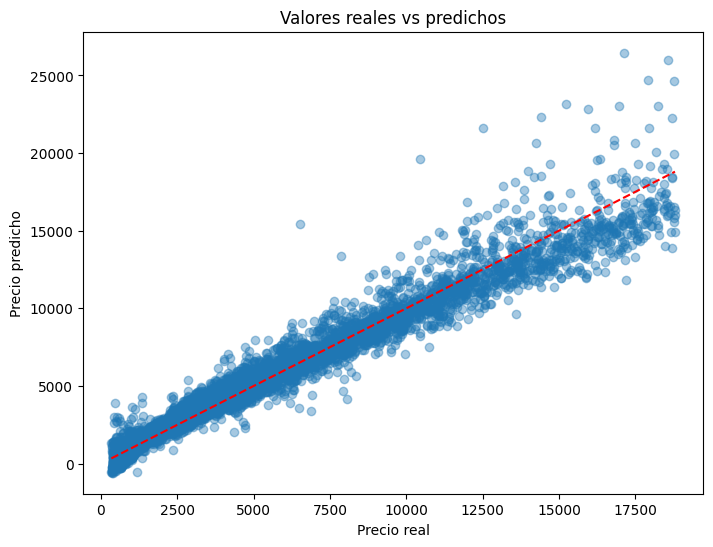

In [24]:
resultados_df = resultados_df.sort_values(
    by='R2',
    ascending=False
).reset_index(drop=True)

print(resultados_df)

predicciones = {
    'Baseline': y_pred_baseline,
    'Ordinal_Robust': y_pred_ordinal,
    'OHE_MinMax': y_pred_ohe,
    'PolynomialDegree2': y_pred_polynomial
}

mejor_modelo = resultados_df.iloc[0]['Modelo']
y_pred_mejor = predicciones[mejor_modelo]

print('Mejor modelo:', mejor_modelo)

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_mejor, alpha=0.4)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--',
    color='red'
)

plt.xlabel('Precio real')
plt.ylabel('Precio predicho')
plt.title('Valores reales vs predichos')
plt.show()

--------------
El modelo PolynomialDegree2 presento el mejor desempeño, seguido de OHE_MinMax, Ordinal_Robust y Baseline. Por lo tanto, incorporar relaciones polinomicas mejoro considerablemente la precision de las predicciones.
--------------

10. Muestra la representación gráfica del pipeline para ubicar la posición de cada elemento dentro del flujo del modelo.
* Obtén los nombres de todas las columnas después del preprocesamiento (numéricas y dummies de categóricas).
* Extrae los nombres de las columnas polinómicas.
* Recupera los coeficientes y el intercepto del modelo de regresión lineal.
* Ordena los coeficientes por su valor absoluto para mostrar los 10 más importantes y da conclusiones sobre cómo los distintos factores influyen en el precio.

In [25]:
from sklearn import set_config

set_config(display='diagram')

modelo_polynomial

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('num', MinMaxScaler(),
                                                  ['carat', 'depth', 'table']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['cut', 'color',
                                                   'clarity'])])),
                ('polynomialfeatures', PolynomialFeatures(include_bias=False)),
                ('linearregression', LinearRegression())])

In [26]:
# --- Nombres de las columnas después del preprocesamiento ---
preprocesador_ajustado = modelo_polynomial.named_steps['columntransformer']
nombres_preprocesados = preprocesador_ajustado.get_feature_names_out()

print(f'Columnas después del preprocesamiento ({len(nombres_preprocesados)}):')
print(nombres_preprocesados)
print()

# --- Nombres de las columnas polinómicas ---
polynomial_transformer = modelo_polynomial.named_steps['polynomialfeatures']
nombres_polynomial = polynomial_transformer.get_feature_names_out(nombres_preprocesados)

print(f'Columnas polinómicas generadas: {len(nombres_polynomial)}')
print('Primeras 10:', nombres_polynomial[:10])
print('Últimas 5: ', nombres_polynomial[-5:])
print()

# --- Coeficientes e intercepto ---
modelo_final = modelo_polynomial.named_steps['linearregression']

print(f'Intercepto: {modelo_final.intercept_:.4f}')
print(f'Número de coeficientes: {len(modelo_final.coef_)}')
print()

# --- Top 10 por valor absoluto ---
coeficientes_df = pd.DataFrame({
    'Variable': nombres_polynomial,
    'Coeficiente': modelo_final.coef_
})
coeficientes_df['Importancia'] = coeficientes_df['Coeficiente'].abs()
coeficientes_df = coeficientes_df.sort_values(by='Importancia', ascending=False).reset_index(drop=True)

print('Top 10 coeficientes por valor absoluto:')
print(coeficientes_df.head(10).to_string(index=False))

Columnas después del preprocesamiento (20):
['num__carat' 'num__depth' 'num__table' 'cat__cut_Good' 'cat__cut_Ideal'
 'cat__cut_Premium' 'cat__cut_Very Good' 'cat__color_E' 'cat__color_F'
 'cat__color_G' 'cat__color_H' 'cat__color_I' 'cat__color_J'
 'cat__clarity_IF' 'cat__clarity_SI1' 'cat__clarity_SI2'
 'cat__clarity_VS1' 'cat__clarity_VS2' 'cat__clarity_VVS1'
 'cat__clarity_VVS2']

Columnas polinómicas generadas: 230
Primeras 10: ['num__carat' 'num__depth' 'num__table' 'cat__cut_Good' 'cat__cut_Ideal'
 'cat__cut_Premium' 'cat__cut_Very Good' 'cat__color_E' 'cat__color_F'
 'cat__color_G']
Últimas 5:  ['cat__clarity_VS2 cat__clarity_VVS1' 'cat__clarity_VS2 cat__clarity_VVS2'
 'cat__clarity_VVS1^2' 'cat__clarity_VVS1 cat__clarity_VVS2'
 'cat__clarity_VVS2^2']

Intercepto: -909.4924
Número de coeficientes: 230

Top 10 coeficientes por valor absoluto:
                    Variable   Coeficiente  Importancia
                num__carat^2  55139.394904 55139.394904
  num__carat cat__clarity_

--------------
El peso del diamante y la claridad destacan entre los factores mas importantes. Tambien se observa que el color influye en la estimacion del precio. Por lo que se podria decir que el valor de un diamante depende de la combinacion de sus diferentes cualidades y no solamente de su peso.
--------------

---

**Declaración de uso de IA**

Si aplica, deberá indicarse la herramienta y el modelo empleado en la entrega, así como la finalidad de su uso (generación de código / depuración / optimización).

Por ejemplo:

*   OpenAI. (2026). *ChatGPT (basado en GPT-4)* [Modelo de lenguaje grande], utilizado para generación de código y depuración. https://chat.openai.com/

---